# Data splits: how much does a random split flatter the model?

The `baselines` experiment trained gradient boosting on random 80/10/10 splits of JARVIS-DFT and reached 0.076 eV/atom for the formation energy. A random split puts close relatives of most test materials into the training set: another polymorph of the same formula, another compound of the same elements, another material of the same structure type. This notebook measures how much of that accuracy survives when the relatives are taken out of the training set, from mild to strict:

| Split | Test set | Taken out of the training set |
|---|---|---|
| random | 10 % of the materials | nothing |
| formula groups | the materials of 10 % of the reduced formulas | the other polymorphs of each test formula |
| chemical-system groups | the materials of 10 % of the chemical systems | every compound of the same elements |
| prototype groups | the materials of 10 % of the structure prototypes | every material of the same structure type |
| leave one element out | all materials that contain element X, for 78 elements | every compound of X |
| prospective | the 38 190 materials added to JARVIS after 2021.8.18 | everything computed later |

The model is the best baseline: gradient boosting on 136 composition and 14 structure features with the same hyperparameters, and the target is the formation energy. For every test material the distance to the training set in feature space is measured too, to see whether the model could have known in advance which predictions are less reliable.

| Section | Content |
|---|---|
| 1 | Data: the 2021.8.18 snapshot and the materials added up to 2025.9.24 |
| 2 | Group labels: reduced formula, chemical system, structure prototype (checked for invariance) |
| 3 | How closely related the test sets are to the training sets |
| 4 | Test error under random, formula, chemical-system and prototype splits |
| 5 | Leave one element out, compared with Li et al. (2024) |
| 6 | Prospective test on the materials added after 2021 |
| 7 | Error against distance to the training set |

In [1]:
import json
import subprocess
import sys
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import spglib
from matplotlib.patches import Rectangle
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
from pymatgen.core import Element
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor

from materials_ml_primer import data, descriptors, splits

QUICK = False        # True only in a fast test run of this notebook
DATA_DIR = Path("../../data")
N_FOLDS = 10           # cross-validation: test, validation and training sets of 10 %, 10 % and 80 %
FOLDS_RUN = range(2) if QUICK else range(N_FOLDS)
MAX_ITER = 200 if QUICK else 5000
MIN_MATERIALS = 200    # leave one element out only for elements that occur in at least this many materials
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10})
summary = []           # rows of the summary table: (quantity, this run, check, check from)


def hgb():
    # the best model of the baselines experiment, same hyperparameters
    return HistGradientBoostingRegressor(learning_rate=0.05, max_iter=MAX_ITER, max_leaf_nodes=63,
                                         early_stopping=True, n_iter_no_change=100, random_state=0)


REPEATED = []   # fits repeated after a thread-pool error, see fit_predict


def fit_predict(fit, val, X_test):
    for attempt in range(3):
        model = hgb()
        try:
            model.fit(X[fit], y[fit], X_val=X[val], y_val=y[val])
            break
        except ValueError as err:
            # On Windows, the thread pool that scikit-learn uses to bin the features can fail when joblib shuts it
            # down ("concurrent send_bytes() calls are not supported", a race in Python's multiprocessing). The fit
            # is deterministic, so it is simply repeated; the count is printed in the summary.
            if "concurrent send_bytes" not in str(err) or attempt == 2:
                raise
            REPEATED.append(len(fit))
    return model, model.predict(X_test)


def plain_log_axis(axis, ticks):
    # log axis with a few plainly written ticks (0.05, 0.1, 0.2) instead of 5 × 10⁻² and crowded minor labels
    axis.set_major_locator(FixedLocator(ticks))
    axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    axis.set_minor_locator(NullLocator())


def mae(p, t):
    return float(np.mean(np.abs(np.asarray(p) - np.asarray(t))))


def r2(p, t):
    t = np.asarray(t)
    return float(1 - np.sum((np.asarray(p) - t) ** 2) / np.sum((t - t.mean()) ** 2))

In [2]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--no-header", "--color=no", "-p", "no:cacheprovider",
                    "../../tests/test_splits.py", "../../tests/test_data.py"], capture_output=True, text=True)
print(r.stdout[-1200:])

........................................................................ [100%]
72 passed in 3.50s



## 1. Data

The training data is the JARVIS-DFT 2021.8.18 snapshot of the `baselines` experiment (one record per JARVIS id). The newest snapshot that jarvis-tools serves, 2025.9.24, contains every material of 2021 and the ones computed since; those are the test set of the prospective split. Before using them, the materials the two snapshots share are compared.

In [3]:
records, _ = data.deduplicate(data.download(data.DFT_3D_2021, DATA_DIR))
latest, repeated = data.deduplicate(data.download(data.DFT_3D_LATEST, DATA_DIR))
if len(latest) != data.DFT_3D_LATEST_SIZE:
    raise RuntimeError(f"jarvis-tools now serves another 'dft_3d' snapshot ({len(latest)} materials); "
                       f"this notebook was run with the 2025.9.24 snapshot ({data.DFT_3D_LATEST_SIZE} materials)")
by_id = {rec["jid"]: rec for rec in latest}
old_ids = {rec["jid"] for rec in records}
added = [rec for rec in latest if rec["jid"] not in old_ids]
same_atoms = sum(by_id[rec["jid"]]["atoms"] == rec["atoms"] for rec in records if rec["jid"] in by_id)
d_ef = max(abs(data.as_float(by_id[rec["jid"]]["formation_energy_peratom"]) - data.as_float(rec["formation_energy_peratom"]))
           for rec in records)
print(f"2021.8.18: {len(records)} materials; 2025.9.24: {len(latest)} materials ({len(repeated)} repeated ids)")
print(f"2021 materials missing from 2025: {len(old_ids - by_id.keys())}; with identical structure: {same_atoms}; "
      f"largest change of formation energy: {d_ef:.4f} eV/atom")
print(f"added after 2021.8.18: {len(added)}")
summary.append(("2021 materials in the 2025 snapshot with identical structure and energy",
                f"{same_atoms}/{len(records)}, max change {d_ef:.4f} eV/atom", "all", "JARVIS 2021.8.18 vs 2025.9.24"))

y = np.array([data.as_float(rec["formation_energy_peratom"]) for rec in records])
y_add = np.array([data.as_float(rec["formation_energy_peratom"]) for rec in added])
for name, v in (("2021", y), ("added", y_add)):
    print(f"formation energy, {name:5s}: {np.isfinite(v).sum()} finite values, mean {v.mean():+.3f} eV/atom, "
          f"MAD {mae(v, v.mean()):.3f} eV/atom, above 5 eV/atom: {(v > 5).sum()}")

t0 = time.perf_counter()
X = np.hstack(descriptors.jarvis_feature_matrices(records))
X_add = np.hstack(descriptors.jarvis_feature_matrices(added))
print(f"features: {X.shape[1]} per material, computed for {len(X) + len(X_add)} materials in {time.perf_counter() - t0:.0f} s")

2021.8.18: 55712 materials; 2025.9.24: 93902 materials (0 repeated ids)
2021 materials missing from 2025: 0; with identical structure: 55712; largest change of formation energy: 0.0000 eV/atom
added after 2021.8.18: 38190
formation energy, 2021 : 55712 finite values, mean -0.832 eV/atom, MAD 0.861 eV/atom, above 5 eV/atom: 0
formation energy, added: 38190 finite values, mean -0.834 eV/atom, MAD 0.777 eV/atom, above 5 eV/atom: 10


features: 150 per material, computed for 93902 materials in 43 s


## 2. Group labels

Three labels define the groups of the group splits:

- **reduced formula**: Fe₄O₆ → Fe₂O₃; all polymorphs of a compound share it;
- **chemical system**: the set of elements, Fe₂O₃ → Fe–O;
- **structure prototype**: the space group and, for each species, its count in the reduced formula and the Wyckoff positions it occupies, with the species themselves left out. NaCl, KCl and MgO share the rock-salt label (space group 225, one species on 4a and one on 4b); zincblende GaAs and ZnS share another.

The space group and the Wyckoff positions come from spglib with a tolerance of 0.1 Å. The same crystal can be described with different Wyckoff letters depending on the choice of origin and axes: zincblende can be written with the cation on 4a and the anion on 4c, but also 4a/4d, 4b/4c or 4b/4d. The descriptions that are equivalent are those related by an operation of the normalizer of the space group; `splits.prototype_label` applies each of these operations (from the Wyckoff-set table of PyXtal) and keeps the smallest result, so that the label does not depend on how the cell was written down. The pytest suite checks this on 21 structures with known prototypes; below it is checked on JARVIS structures with a random origin, atom order and orientation.

In [4]:
def labels_of(recs):
    formula, system, proto = [], [], []
    for rec in recs:
        lat, frac, sp = data.structure_arrays(rec["atoms"])
        formula.append(splits.reduced_formula(sp))
        system.append(splits.chemical_system(sp))
        label = splits.prototype_label(lat, frac, sp)
        proto.append(label if label is not None else ("no symmetry found", rec["jid"]))   # its own group
    return formula, system, proto


t0 = time.perf_counter()
formula, system, proto = labels_of(records)
formula_add, system_add, proto_add = labels_of(added)
print(f"labels for {len(records) + len(added)} materials in {time.perf_counter() - t0:.0f} s; "
      f"no symmetry found: {sum(p[0] == 'no symmetry found' for p in proto + proto_add)}")
agree = np.mean([p[0] == int(rec["spg_number"]) for p, rec in zip(proto, records, strict=True)])
print(f"space group equal to the JARVIS spg_number: {agree:.1%}")
summary.append(("space group from spglib (0.1 Å) equal to JARVIS spg_number", f"{agree:.1%}", "most",
                "JARVIS 2021.8.18"))
for name, labels in (("reduced formulas", formula), ("chemical systems", system), ("prototypes", proto)):
    c = Counter(labels)
    print(f"{name:17s} {len(c):6d} groups, {sum(v == 1 for v in c.values()):6d} with a single material, "
          f"largest {max(c.values())}")


def show(label):
    sg, sites = label
    return f"SG {sg:3d}  " + "  ".join(f"{n}×{''.join(w)}" for n, w in sites)


print("\nlargest structure prototypes (count×Wyckoff letters per species), with example formulas:")
for label, n in Counter(proto).most_common(8):
    examples = [rec["formula"] for rec, p in zip(records, proto, strict=True) if p == label][:4]
    print(f"  {n:5d}  {show(label):40s} {', '.join(examples)}")

labels for 93902 materials in 214 s; no symmetry found: 0
space group equal to the JARVIS spg_number: 98.4%
reduced formulas   39862 groups,  31542 with a single material, largest 87
chemical systems   23445 groups,  13492 with a single material, largest 161
prototypes          7390 groups,   3951 with a single material, largest 4084

largest structure prototypes (count×Wyckoff letters per species), with example formulas:
   4084  SG 225  1×a  1×b  2×c                    LiSiCu2, HfScCo2, TiFe2As, TiFe2Sb
   1402  SG 216  1×a  1×c  4×e                    Ba4NaBi, LuNi4Sn, Ba4TaZn, Ba4CaRe
   1384  SG  99  1×a  1×b  2×ab                   Be2CuIr, Be2ReSi, Be2VMo, Be2FeCl
   1115  SG 221  1×a  1×b  3×c                    SrFeO3, RbVF3, CeTiO3, RbAlO3
   1022  SG 225  1×a  1×b  2×c  6×e               Ba2UFeO6, Ba2EuNbO6, Ba2CoMoO6, Sr2CoMoO6
    919  SG 216  1×a  1×b  1×c                    KBaZn, UNiSn, KBaNb, BaNaSc
    902  SG 221  1×a  3×c                         RbF3, Ni3Hg, Th3U, L

In [5]:
def label_without_normalizer(lat, frac, sp):
    # the label as spglib's standardization gives it, without trying the equivalent descriptions
    kinds = sorted(set(sp))
    ds = spglib.get_symmetry_dataset((lat, frac, [kinds.index(s) + 1 for s in sp]), symprec=0.1)
    letters = {}
    for atom in set(ds.crystallographic_orbits.tolist()):
        letters.setdefault(sp[atom], []).append(ds.wyckoffs[atom])
    counts = dict(splits.reduced_formula(sp))
    return int(ds.number), tuple(sorted((counts[s], tuple(sorted(w))) for s, w in letters.items()))


rng = np.random.default_rng(0)
sample = rng.choice(len(records), 30 if QUICK else 500, replace=False)
kept, kept_raw = 0, 0
with warnings.catch_warnings():
    warnings.simplefilter("ignore", DeprecationWarning)   # spglib, see splits.prototype_label
    for i in sample:
        lat, frac, sp = data.structure_arrays(records[i]["atoms"])
        perm = rng.permutation(len(sp))
        rot = np.linalg.qr(rng.normal(size=(3, 3)))[0]
        moved = (frac[perm] + rng.random(3)) % 1.0
        if rng.random() < 0.5:
            moved = (-moved) % 1.0
        sp_moved = [sp[k] for k in perm]
        kept += splits.prototype_label(lat @ rot.T, moved, sp_moved) == proto[i]
        kept_raw += label_without_normalizer(lat @ rot.T, moved, sp_moved) == label_without_normalizer(lat, frac, sp)
print(f"random origin, atom order, orientation and (half the time) inversion, {len(sample)} JARVIS structures:")
print(f"  label unchanged: {kept}/{len(sample)}; without the normalizer step: {kept_raw}/{len(sample)}")
summary.append(("prototype label unchanged under a random origin, atom order, rotation, inversion",
                f"{kept}/{len(sample)}", f"{len(sample)}/{len(sample)}", "invariance (without normalizer: "
                f"{kept_raw}/{len(sample)})"))

random origin, atom order, orientation and (half the time) inversion, 500 JARVIS structures:
  label unchanged: 500/500; without the normalizer step: 321/500


## 3. How closely related are test and training sets?

Every split is a 10-fold cross-validation. The materials are divided into 10 folds of nearly equal size; in a group split every group lies in one fold, the groups being taken from the largest to the smallest and each put into the fold with the fewest materials so far (as in scikit-learn's `GroupKFold`). Each fold is the test set once, the next fold is the validation set for early stopping, and the other eight folds are the training set: 80/10/10, as in the baselines, and the validation set is grouped the same way as the test set. Every material is predicted once, by a model that saw neither it nor its group. (A single 10 % test set of whole groups would instead depend heavily on whether it happened to contain one of the large groups: the largest prototype, the full-Heusler type, holds 4084 of the 93 902 materials of both snapshots.)

For every test material the table counts how often its training set contains

- a **polymorph**: a material with the same reduced formula;
- the **same chemical system**;
- a **larger system** that contains its system (Li–O in the test set, Li–Mn–O in the training set);
- a **smaller system** with at least two elements inside its system (Li–Mn–O in the test set, Li–O in the training set);
- **none** of the three;
- a material of the **same prototype**.

In [6]:
FOLDS = {
    "random": splits.random_folds(len(records), N_FOLDS, seed=0),
    "formula groups": splits.group_folds(formula, N_FOLDS, seed=0),
    "chemical-system groups": splits.group_folds(system, N_FOLDS, seed=0),
    "prototype groups": splits.group_folds(proto, N_FOLDS, seed=0),
}
RELATIONS = ["polymorph", "same", "larger", "smaller", "none", "prototype"]


def relations(train, test_formula, test_system, test_proto):
    rel = splits.system_relations([system[i] for i in train], test_system)
    train_formula, train_proto = {formula[i] for i in train}, {proto[i] for i in train}
    rel["polymorph"] = np.array([f in train_formula for f in test_formula])
    rel["prototype"] = np.array([p in train_proto for p in test_proto])
    return rel


print(f"{'test materials whose training set has':30s} {'fold sizes':>13s}" + "".join(f"{k:>11s}" for k in RELATIONS))
relation_table = {}
for name, folds in FOLDS.items():
    hits = np.zeros(len(RELATIONS))
    for k in FOLDS_RUN:
        tr, va, te = splits.fold_split(folds, k)
        rel = relations(tr, [formula[i] for i in te], [system[i] for i in te], [proto[i] for i in te])
        hits += [rel[r].sum() for r in RELATIONS]
    n_tested = sum(np.sum(folds == k) for k in FOLDS_RUN)
    relation_table[name] = hits / n_tested
    sizes = np.bincount(folds)
    print(f"{name:30s} {sizes.min():6d}-{sizes.max():6d}" + "".join(f"{v:11.1%}" for v in relation_table[name]))

test materials whose training set has    fold sizes  polymorph       same     larger    smaller       none  prototype


random                           5571-  5572      39.0%      72.2%      53.1%      75.5%       0.3%      91.9%


formula groups                   5571-  5572       0.0%      62.5%      53.1%      75.5%       0.3%      90.4%


chemical-system groups           5571-  5572       0.0%       0.0%      52.8%      74.6%       1.3%      90.0%


prototype groups                 5571-  5572      30.8%      68.3%      52.7%      75.5%       0.3%       0.0%


## 4. Test error under the group splits

Gradient boosting with composition and structure features, trained once per fold. The MAE is over all materials (each predicted once), the spread is the standard deviation of the MAE over the folds, and the trivial baseline ("MAE of mean") predicts the mean of the training set for every test material. The last row checks the protocol: the chemical-system folds again, for the first three folds, but with early stopping on a random validation set drawn from the non-test materials.

In [7]:
t0 = time.perf_counter()
results, cv = {}, {}
for name, folds in FOLDS.items():
    pred, dist = np.full(len(y), np.nan), np.full(len(y), np.nan)
    per_fold, base, iters = [], np.full(len(y), np.nan), []
    for k in FOLDS_RUN:
        tr, va, te = splits.fold_split(folds, k)
        model, p = fit_predict(tr, va, X[te])
        pred[te], base[te] = p, y[tr].mean()
        dist[te] = splits.distance_to_train(X[tr], X[te])
        per_fold.append(mae(p, y[te]))
        iters.append(model.n_iter_)
    done = np.isfinite(pred)
    cv[name] = {"pred": pred, "dist": dist, "done": done}
    results[name] = {"mae": mae(pred[done], y[done]), "sd": float(np.std(per_fold)), "r2": r2(pred[done], y[done]),
                     "base": mae(base[done], y[done]), "iters": float(np.mean(iters)), "per_fold": per_fold}

check_folds = list(FOLDS_RUN)[:3]
grouped, randomval = [], []
for k in check_folds:
    tr, va, te = splits.fold_split(FOLDS["chemical-system groups"], k)
    pool = np.random.default_rng(k).permutation(np.concatenate([tr, va]))
    model, p = fit_predict(pool[len(va):], pool[:len(va)], X[te])
    randomval.append(mae(p, y[te]))
    grouped.append(results["chemical-system groups"]["per_fold"][k])
n_models = len(FOLDS) * len(FOLDS_RUN) + len(check_folds)
print(f"{n_models} models in {time.perf_counter() - t0:.0f} s\n")

print(f"{'split, 10-fold cross-validation':32s} {'test MAE (eV/atom)':>22s} {'R²':>7s} {'MAE of mean':>12s} {'iterations':>11s}")
for name, v in results.items():
    print(f"{name:32s} {v['mae']:12.4f} ± {v['sd']:.4f} (sd) {v['r2']:7.3f} {v['base']:12.3f} {v['iters']:11.0f}")
print(f"\nchemical-system folds {check_folds}: MAE with a grouped validation set {np.mean(grouped):.4f}, "
      f"with a random one {np.mean(randomval):.4f} eV/atom")
summary.append(("random 10-fold cross-validation: test MAE (eV/atom)", f"{results['random']['mae']:.3f}",
                "0.076 ± 0.002", "baselines experiment (3 random 80/10/10 splits)"))

43 models in 1647 s

split, 10-fold cross-validation      test MAE (eV/atom)      R²  MAE of mean  iterations
random                                 0.0763 ± 0.0020 (sd)   0.983        0.861        5000
formula groups                         0.0937 ± 0.0037 (sd)   0.977        0.861        4778
chemical-system groups                 0.0972 ± 0.0038 (sd)   0.976        0.861        4857
prototype groups                       0.1448 ± 0.0349 (sd)   0.947        0.864        3640

chemical-system folds [0, 1, 2]: MAE with a grouped validation set 0.1000, with a random one 0.0979 eV/atom


## 5. Leave one element out

For every element that occurs in at least 200 materials, all materials containing it form the test set; the model never sees a compound of that element. The other materials are split by chemical system into training (90 %) and validation (10 %) sets. Li et al. (arXiv:2406.06489, 2024) ran the same test with XGBoost on 145 composition and 128 structure features for the JARVIS 2022.12.12 snapshot (76 000 materials, formation energies above 5 eV/atom removed); their R² values per element, read from their Supplementary Figure 2, are the reference here.

In [8]:
LI2024_XGB_JARVIS = {  # leave-one-element-out R2, XGB, JARVIS 2022.12.12; Li et al., arXiv:2406.06489, Supplementary Fig. 2
    "H": 0.339, "Li": 0.904, "Be": 0.806, "B": 0.892, "C": 0.789, "N": 0.606, "O": 0.474, "F": -0.207, "Na": 0.95,
    "Mg": 0.979, "Al": 0.926, "Si": 0.946, "P": 0.921, "S": 0.883, "Cl": 0.893, "K": 0.985, "Ca": 0.982,
    "Sc": 0.973, "Ti": 0.981, "V": 0.981, "Cr": 0.976, "Mn": 0.966, "Fe": 0.988, "Co": 0.984, "Ni": 0.968,
    "Cu": 0.975, "Zn": 0.975, "Ga": 0.959, "Ge": 0.974, "As": 0.926, "Se": 0.946, "Br": 0.953, "Rb": 0.971,
    "Sr": 0.985, "Y": 0.982, "Zr": 0.976, "Nb": 0.974, "Mo": 0.961, "Tc": 0.947, "Ru": 0.972, "Rh": 0.899,
    "Pd": 0.848, "Ag": 0.933, "Cd": 0.966, "In": 0.969, "Sn": 0.962, "Sb": 0.961, "Te": 0.946, "I": 0.945,
    "Ba": 0.96, "La": 0.99, "Ce": 0.983, "Pr": 0.995, "Nd": 0.969, "Pm": 0.992, "Sm": 0.994, "Eu": 0.944,
    "Tb": 0.993, "Dy": 0.997, "Ho": 0.997, "Er": 0.995, "Tm": 0.985, "Yb": 0.96, "Lu": 0.981, "Hf": 0.978,
    "Ta": 0.981, "W": 0.944, "Re": 0.963, "Os": 0.957, "Ir": 0.909, "Pt": 0.857, "Au": 0.918, "Hg": 0.88,
    "Tl": 0.93, "Pb": 0.859, "Bi": 0.962, "Ac": 0.98, "Th": 0.974, "Pa": 0.968, "U": 0.975, "Pu": 0.92
}

counts = Counter(e for s in system for e in s)
ELEMENTS = sorted((e for e, c in counts.items() if c >= MIN_MATERIALS), key=lambda e: Element(e).Z)
print(f"{len(ELEMENTS)} of {len(counts)} elements occur in at least {MIN_MATERIALS} materials")
if QUICK:
    ELEMENTS = ["Li", "O", "F", "Fe"]

t0 = time.perf_counter()
loeo = {}
for e in ELEMENTS:
    test = np.array([i for i, s in enumerate(system) if e in s])
    rest = np.setdiff1d(np.arange(len(records)), test)
    tr_r, va_r, _ = splits.group_split([system[i] for i in rest], seed=0, fractions=(0.9, 0.1, 0.0))
    tr, va = rest[tr_r], rest[va_r]
    model, p = fit_predict(tr, va, X[test])
    loeo[e] = {"n": len(test), "mae": mae(p, y[test]), "r2": r2(p, y[test]), "bias": float(np.mean(p - y[test])),
               "err": np.abs(p - y[test]), "dist": splits.distance_to_train(X[tr], X[test])}
print(f"{len(ELEMENTS)} models in {time.perf_counter() - t0:.0f} s")

r2s = {e: v["r2"] for e, v in loeo.items()}
worst = sorted(r2s, key=r2s.get)
print(f"R² > 0.95: {np.mean([v > 0.95 for v in r2s.values()]):.0%} of the elements; "
      f"median MAE {np.median([v['mae'] for v in loeo.values()]):.3f} eV/atom")
print(f"{'worst elements':16s} {'n':>6s} {'MAE':>7s} {'R²':>7s} {'bias':>7s}  (bias = mean of predicted − DFT, eV/atom)")
for e in worst[:10]:
    v = loeo[e]
    print(f"  {e:14s} {v['n']:6d} {v['mae']:7.3f} {v['r2']:7.3f} {v['bias']:+7.3f}")

78 of 89 elements occur in at least 200 materials


78 models in 3137 s
R² > 0.95: 62% of the elements; median MAE 0.134 eV/atom
worst elements        n     MAE      R²    bias  (bias = mean of predicted − DFT, eV/atom)
  F                3911   0.824  -0.080  +0.792
  N                2789   0.550   0.515  -0.452
  H                2769   0.465   0.539  +0.411
  O               14992   0.491   0.555  +0.368
  Be               4548   0.252   0.751  -0.009
  C                2812   0.302   0.785  -0.214
  Pb               1359   0.254   0.857  +0.108
  Pt               1398   0.180   0.892  +0.140
  P                2668   0.252   0.894  +0.186
  S                3940   0.198   0.897  +0.121


elements in both: 78; Spearman correlation of R²: 0.95
R² > 0.95: this run 62%, Li et al. 63% (same elements)
six worst, this run:   F -0.08, N 0.52, H 0.54, O 0.55, Be 0.75, C 0.78
six worst, Li et al.:  F -0.21, H 0.34, O 0.47, N 0.61, C 0.79, Be 0.81


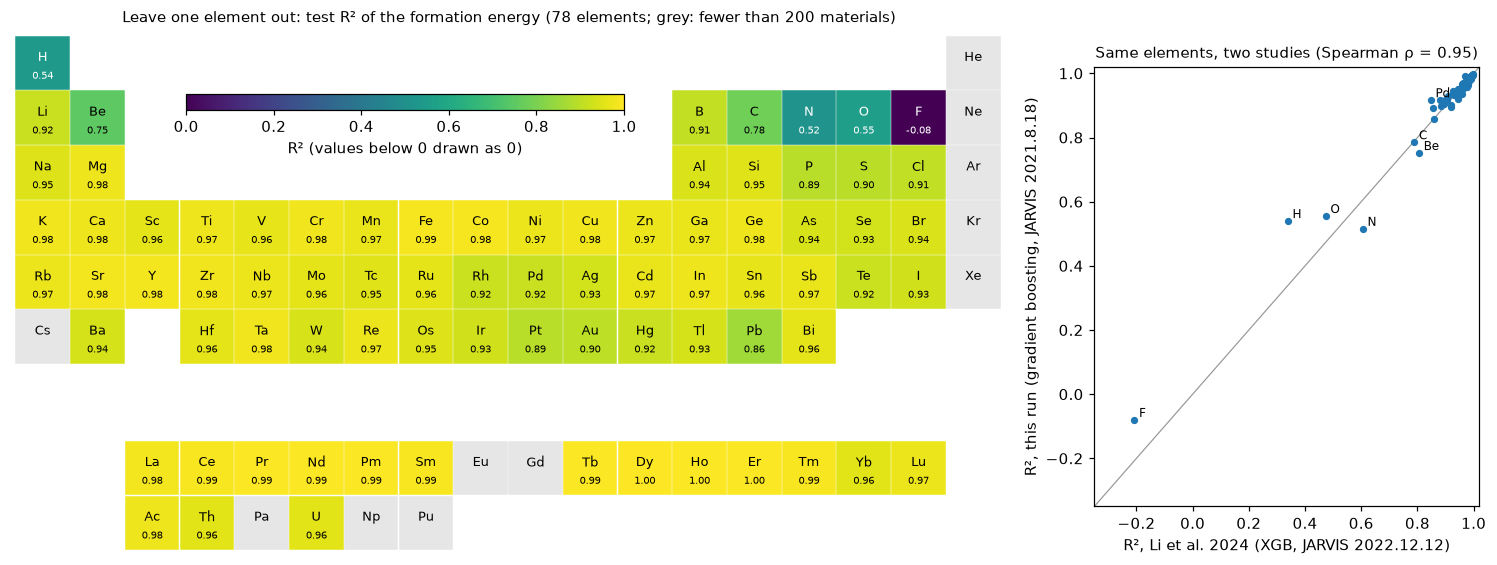

In [9]:
common = [e for e in ELEMENTS if e in LI2024_XGB_JARVIS]
ours = np.array([r2s[e] for e in common])
theirs = np.array([LI2024_XGB_JARVIS[e] for e in common])
rho = spearmanr(ours, theirs).statistic
print(f"elements in both: {len(common)}; Spearman correlation of R²: {rho:.2f}")
print(f"R² > 0.95: this run {np.mean(ours > 0.95):.0%}, Li et al. {np.mean(theirs > 0.95):.0%} (same elements)")
print("six worst, this run:  ", ", ".join(f"{e} {r2s[e]:.2f}" for e in sorted(common, key=r2s.get)[:6]))
print("six worst, Li et al.: ", ", ".join(f"{e} {LI2024_XGB_JARVIS[e]:.2f}"
                                          for e in sorted(common, key=LI2024_XGB_JARVIS.get)[:6]))
summary.append(("leave one element out: Spearman correlation of R² per element with Li et al.",
                f"{rho:.2f} ({len(common)} elements)", "high", "Li et al. 2024, XGB on JARVIS 2022.12.12"))
summary.append(("leave one element out: elements with R² > 0.95", f"{np.mean(ours > 0.95):.0%}",
                f"{np.mean(theirs > 0.95):.0%}", "Li et al. 2024, same elements"))
summary.append(("leave one element out: the six elements with the lowest R²",
                " ".join(sorted(common, key=r2s.get)[:6]), " ".join(sorted(common, key=LI2024_XGB_JARVIS.get)[:6]),
                "Li et al. 2024"))


def table_position(symbol):
    z = Element(symbol).Z
    if 57 <= z <= 71:
        return 8.4, 3 + z - 57
    if 89 <= z <= 103:
        return 9.4, 3 + z - 89
    el = Element(symbol)
    return float(el.row), el.group


fig = plt.figure(figsize=(14, 5.4))
ax = fig.add_axes([0.02, 0.06, 0.66, 0.88])
cmap = plt.get_cmap("viridis")
for e in counts:
    row, col = table_position(e)
    tested = e in r2s
    color = cmap(np.clip(r2s[e], 0, 1)) if tested else (0.9, 0.9, 0.9, 1)
    ax.add_patch(Rectangle((col - 0.5, row - 0.5), 0.96, 0.96, color=color))
    dark = tested and np.clip(r2s[e], 0, 1) < 0.6
    ax.text(col - 0.02, row - 0.12, e, ha="center", va="center", fontsize=8.5, color="w" if dark else "k")
    if tested:
        ax.text(col - 0.02, row + 0.22, f"{r2s[e]:.2f}", ha="center", va="center", fontsize=6.5,
                color="w" if dark else "k")
ax.set_xlim(0.4, 18.6)
ax.set_ylim(9.95, 0.4)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title(f"Leave one element out: test R² of the formation energy ({len(r2s)} elements; grey: fewer than "
             f"{MIN_MATERIALS} materials)", fontsize=10)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
cax = ax.inset_axes([3.6, 1.55, 8.0, 0.28], transform=ax.transData)   # empty space above the transition metals
fig.colorbar(sm, cax=cax, orientation="horizontal", label="R² (values below 0 drawn as 0)")

ax2 = fig.add_axes([0.73, 0.14, 0.25, 0.74])
ax2.plot([-0.4, 1.02], [-0.4, 1.02], color="0.6", lw=0.8, zorder=0)
ax2.scatter(theirs, ours, s=14, color="C0")
for e, a, b in zip(common, theirs, ours, strict=True):
    if min(a, b) < 0.85:
        ax2.annotate(e, (a, b), xytext=(3, 2), textcoords="offset points", fontsize=8)
ax2.set_xlabel("R², Li et al. 2024 (XGB, JARVIS 2022.12.12)")
ax2.set_ylabel("R², this run (gradient boosting, JARVIS 2021.8.18)")
ax2.set_title(f"Same elements, two studies (Spearman ρ = {rho:.2f})", fontsize=10)
lo = min(-0.35, ours.min() - 0.05, theirs.min() - 0.05)
ax2.set_xlim(lo, 1.02)
ax2.set_ylim(lo, 1.02)
fig.savefig("figures/leave_one_element_out.png", bbox_inches="tight")
plt.show()

## 6. Prospective test: the materials added after 2021

The model is trained on the 2021.8.18 snapshot alone (90 % training, 10 % validation, split by chemical system) and predicts the 38 190 materials that JARVIS added up to 2025.9.24. This is the situation in which a model is used: on materials computed after it was trained.

In [10]:
tr_p, va_p, _ = splits.group_split(system, seed=0, fractions=(0.9, 0.1, 0.0))
model, p_add = fit_predict(tr_p, va_p, X_add)
err_add = np.abs(p_add - y_add)
dist_add = splits.distance_to_train(X[tr_p], X_add)
rel_add = relations(tr_p, formula_add, system_add, proto_add)
print(f"prospective test, {len(added)} materials: MAE {mae(p_add, y_add):.4f} eV/atom, R² {r2(p_add, y_add):.3f}, "
      f"predicting the training mean {mae(np.full(len(y_add), y[tr_p].mean()), y_add):.3f} eV/atom, "
      f"{model.n_iter_} iterations")
print(f"\n{'added materials whose training set has':40s} {'share':>7s} {'MAE yes':>9s} {'MAE no':>9s}")
for k in RELATIONS:
    m = rel_add[k]
    print(f"  {k:38s} {m.mean():7.1%} {mae(p_add[m], y_add[m]) if m.any() else np.nan:9.3f}"
          f" {mae(p_add[~m], y_add[~m]) if (~m).any() else np.nan:9.3f}")
print(f"\n{'by JARVIS dimensionality':40s} {'n':>7s} {'MAE':>9s}")
dims = np.array([rec["dimensionality"] for rec in added])
for d, n in Counter(dims).most_common():
    print(f"  {d:38s} {n:7d} {mae(p_add[dims == d], y_add[dims == d]):9.3f}")


def has_icsd(rec):
    # JARVIS lists the ICSD ids of the experimental structures a material matches; empty for hypothetical ones
    return str(rec.get("icsd", "")).strip() not in ("", "na", "None")


icsd_old = np.mean([has_icsd(rec) for rec in records])
icsd_add = np.array([has_icsd(rec) for rec in added])
print(f"\nwith an ICSD id: {icsd_old:.1%} of the 2021 materials, {icsd_add.mean():.1%} of the added ones; "
      f"MAE on the added ones with an ICSD id {mae(p_add[icsd_add], y_add[icsd_add]):.3f}, "
      f"without {mae(p_add[~icsd_add], y_add[~icsd_add]):.3f} eV/atom")

prospective test, 38190 materials: MAE 0.1092 eV/atom, R² 0.960, predicting the training mean 0.778 eV/atom, 5000 iterations

added materials whose training set has     share   MAE yes    MAE no
  polymorph                                21.7%     0.068     0.121
  same                                     61.2%     0.105     0.116
  larger                                   52.1%     0.118     0.099
  smaller                                  73.5%     0.098     0.140
  none                                      1.5%     0.419     0.104
  prototype                                88.0%     0.109     0.109

by JARVIS dimensionality                       n       MAE
  3D-bulk                                  20901     0.091
  intercalated ion                         14175     0.118
  2D-bulk                                   1530     0.176
  0D-bulk                                    734     0.210
  1D-bulk                                    402     0.162
  na                                

## 7. Error against distance to the training set

For each test material, the distance to the training set is the mean Euclidean distance to its five nearest training materials in the space of the 150 features, each standardized with the training mean and standard deviation (`splits.distance_to_train`; root-mean-square difference per feature). If the error grows with this distance, a model can flag its own unreliable predictions before any DFT check. Two numbers summarize each test set: the Spearman correlation between distance and absolute error, and how many of the 10 % largest errors fall among the 10 % most distant materials (10 % if distance carried no information). The last column compares the test sets at the same distance: the MAE of the test materials at a distance between 0.2 and 0.4.

test set                       n  median distance     MAE  Spearman  top-10 % overlap  MAE at distance 0.2-0.4
random                     55712            0.272   0.076      0.30               21%     0.080 (57% of the set)
chemical-system groups     55712            0.307   0.097      0.23               22%     0.092 (61% of the set)
prototype groups           55712            0.356   0.145      0.24               15%     0.134 (51% of the set)
leave one element out     161999            0.392   0.209      0.31               24%     0.153 (45% of the set)


prospective                38190            0.340   0.109      0.29               24%     0.103 (54% of the set)


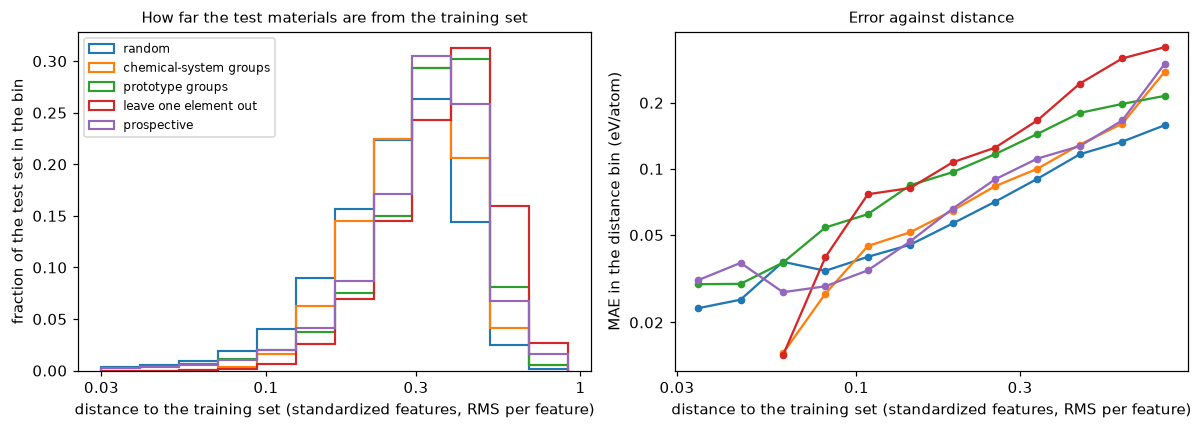

In [11]:
cases = {}
for name in ("random", "chemical-system groups", "prototype groups"):
    c = cv[name]
    cases[name] = (c["dist"][c["done"]], np.abs(c["pred"] - y)[c["done"]])
cases["leave one element out"] = (np.concatenate([v["dist"] for v in loeo.values()]),
                                  np.concatenate([v["err"] for v in loeo.values()]))
cases["prospective"] = (dist_add, err_add)


def top_overlap(dist, err, q=0.1):
    k = max(1, int(q * len(err)))
    return len(set(np.argsort(-dist)[:k]) & set(np.argsort(-err)[:k])) / k


BAND = (0.2, 0.4)   # a distance range that holds a large part of every test set
print(f"{'test set':24s} {'n':>7s} {'median distance':>16s} {'MAE':>7s} {'Spearman':>9s} {'top-10 % overlap':>17s}"
      f" {'MAE at distance 0.2-0.4':>24s}")
for name, (dist, err) in cases.items():
    band = (dist >= BAND[0]) & (dist < BAND[1])
    print(f"{name:24s} {len(err):7d} {np.median(dist):16.3f} {err.mean():7.3f} {spearmanr(dist, err).statistic:9.2f}"
          f" {top_overlap(dist, err):17.0%} {err[band].mean():9.3f} ({band.mean():.0%} of the set)")

pooled = np.concatenate([d for d, _ in cases.values()])
edges = np.geomspace(np.quantile(pooled, 0.005), np.quantile(pooled, 0.995), 13)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for k, (name, (dist, err)) in enumerate(cases.items()):
    axes[0].hist(dist, bins=edges, histtype="step", weights=np.full(len(dist), 1 / len(dist)), color=f"C{k}",
                 label=name, lw=1.4)
    idx = np.digitize(dist, edges) - 1
    centers, values = [], []
    for b in range(len(edges) - 1):
        sel = idx == b
        if sel.sum() >= 30:
            centers.append(np.sqrt(edges[b] * edges[b + 1]))
            values.append(err[sel].mean())
    axes[1].plot(centers, values, "o-", ms=4, color=f"C{k}", label=name)
for a in axes:
    a.set_xscale("log")
    plain_log_axis(a.xaxis, [0.003, 0.01, 0.03, 0.1, 0.3, 1])
    a.set_xlabel("distance to the training set (standardized features, RMS per feature)")
axes[0].set_ylabel("fraction of the test set in the bin")
axes[0].set_title("How far the test materials are from the training set", fontsize=10)
axes[1].set_yscale("log")
plain_log_axis(axes[1].yaxis, [0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1])
axes[1].set_ylabel("MAE in the distance bin (eV/atom)")
axes[1].set_title("Error against distance", fontsize=10)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig("figures/error_vs_distance.png", bbox_inches="tight")
plt.show()

## 8. Summary

All test errors of this notebook in one figure, and the checks of the numbers.

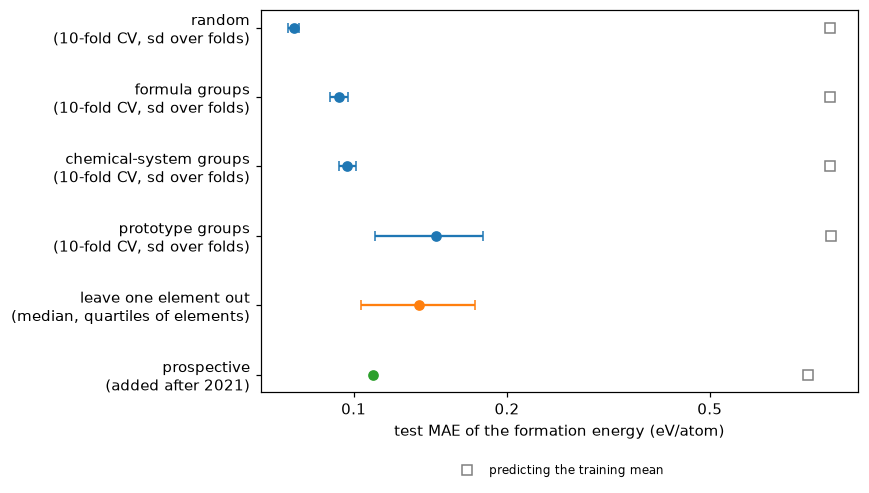

quantity                                                                                                        this run          check  check from
2021 materials in the 2025 snapshot with identical structure and energy           55712/55712, max change 0.0000 eV/atom            all  JARVIS 2021.8.18 vs 2025.9.24
space group from spglib (0.1 Å) equal to JARVIS spg_number                                                         98.4%           most  JARVIS 2021.8.18
prototype label unchanged under a random origin, atom order, rotation, inversion                                 500/500        500/500  invariance (without normalizer: 321/500)
random 10-fold cross-validation: test MAE (eV/atom)                                                                0.076  0.076 ± 0.002  baselines experiment (3 random 80/10/10 splits)
leave one element out: Spearman correlation of R² per element with Li et al.                          0.95 (78 elements)           high  Li et al. 2024, XGB on JARVIS 2

In [12]:
names = ["random", "formula groups", "chemical-system groups", "prototype groups"]
fig, ax = plt.subplots(figsize=(8, 4.6))
ypos = np.arange(len(names) + 2)[::-1]
for k, name in enumerate(names):
    v = results[name]
    ax.errorbar(v["mae"], ypos[k], xerr=v["sd"], fmt="o", color="C0", capsize=3)
    ax.plot(v["base"], ypos[k], "s", mfc="none", color="0.5")
e_mae = np.array([v["mae"] for v in loeo.values()])
q1, med, q3 = np.percentile(e_mae, [25, 50, 75])
ax.errorbar(med, ypos[4], xerr=[[med - q1], [q3 - med]], fmt="o", color="C1", capsize=3)
ax.plot(mae(p_add, y_add), ypos[5], "o", color="C2")
ax.plot(mae(np.full(len(y_add), y[tr_p].mean()), y_add), ypos[5], "s", mfc="none", color="0.5")
ax.set_yticks(ypos, [n + "\n(10-fold CV, sd over folds)" for n in names]
              + ["leave one element out\n(median, quartiles of elements)", "prospective\n(added after 2021)"])
ax.set_xscale("log")
plain_log_axis(ax.xaxis, [0.05, 0.1, 0.2, 0.5, 1])
ax.set_xlabel("test MAE of the formation energy (eV/atom)")
ax.plot([], [], "s", mfc="none", color="0.5", label="predicting the training mean")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16), frameon=False)
fig.tight_layout()
fig.savefig("figures/split_errors.png", bbox_inches="tight")
plt.show()

w = [max(len(r[j]) for r in summary) for j in range(3)]
print(f"{'quantity':{w[0]}s}  {'this run':>{w[1]}s}  {'check':>{w[2]}s}  check from")
for q_, a_, b_, src in summary:
    print(f"{q_:{w[0]}s}  {a_:>{w[1]}s}  {b_:>{w[2]}s}  {src}")
print()
print(f"fits repeated after a thread-pool error on Windows (the results do not change): {len(REPEATED)}")

## 9. Data for the interactive page

The numbers behind the figures, per element, per split and per distance bin, and a random sample of 1000 predictions per test set are written to `data_splits_results.json`; `_build/build_web_data_splits.py` turns it into the interactive page `web/data_splits.html`.

In [13]:
def num(x, digits=4):
    x = float(x)
    return round(x, digits) if np.isfinite(x) else None


def mae_or_none(mask):
    return num(mae(p_add[mask], y_add[mask])) if mask.any() else None


def binned(dist, err):
    idx = np.digitize(dist, edges) - 1
    count = np.array([np.sum(idx == b) for b in range(len(edges) - 1)])
    value = [num(err[idx == b].mean()) if count[b] >= 30 else None for b in range(len(edges) - 1)]
    return count, value


distance_sets = {}
for name, (dist, err) in cases.items():
    count, value = binned(dist, err)
    band = (dist >= BAND[0]) & (dist < BAND[1])
    distance_sets[name] = {
        "n": len(err), "median": num(np.median(dist)), "mae": num(err.mean()),
        "spearman": num(spearmanr(dist, err).statistic, 3), "top10": num(top_overlap(dist, err), 3),
        "band_mae": num(err[band].mean()), "band_share": num(band.mean(), 3),
        "fraction": [num(c / len(dist), 5) for c in np.histogram(dist, bins=edges)[0]],
        "count": count.tolist(), "binned_mae": value}

rng = np.random.default_rng(0)
sample = np.sort(rng.choice(len(records), 1000, replace=False))
sample_add = np.sort(rng.choice(len(added), 1000, replace=False))
export = {
    "about": {"train_snapshot": "JARVIS-DFT 2021.8.18", "latest_snapshot": "JARVIS-DFT 2025.9.24",
              "n_2021": len(records), "n_added": len(added), "n_folds": N_FOLDS, "min_materials": MIN_MATERIALS,
              "target": "formation energy per atom (eV/atom)", "quick_test_run": QUICK},
    "relations": {"columns": RELATIONS, "rows": {k: [num(v, 4) for v in vals] for k, vals in relation_table.items()}},
    "cv": {k: {"mae": num(v["mae"]), "sd": num(v["sd"]), "r2": num(v["r2"]), "base": num(v["base"]),
               "iters": num(v["iters"], 0), "per_fold": [num(x) for x in v["per_fold"]]} for k, v in results.items()},
    "loeo": {e: {"z": Element(e).Z, "pos": [float(table_position(e)[0]), int(table_position(e)[1])], "n": v["n"],
                 "mae": num(v["mae"]), "r2": num(v["r2"]), "bias": num(v["bias"]), "li2024": LI2024_XGB_JARVIS.get(e)}
             for e, v in loeo.items()},
    "untested": {e: {"z": Element(e).Z, "pos": [float(table_position(e)[0]), int(table_position(e)[1])], "n": c}
                 for e, c in counts.items() if e not in loeo},
    "loeo_spearman_li2024": num(rho, 3),
    "prospective": {
        "mae": num(mae(p_add, y_add)), "r2": num(r2(p_add, y_add)), "iters": int(model.n_iter_),
        "base": num(mae(np.full(len(y_add), y[tr_p].mean()), y_add)),
        "relations": {k: {"share": num(rel_add[k].mean()), "mae_yes": mae_or_none(rel_add[k]),
                          "mae_no": mae_or_none(~rel_add[k])} for k in RELATIONS},
        "dimensionality": [{"label": d, "n": n, "mae": mae_or_none(dims == d)} for d, n in Counter(dims).most_common()],
        "icsd": {"share_2021": num(icsd_old), "share_added": num(icsd_add.mean()), "mae_with": mae_or_none(icsd_add),
                 "mae_without": mae_or_none(~icsd_add)}},
    "distance": {"edges": [num(e, 5) for e in edges], "band": list(BAND), "sets": distance_sets},
    "parity": {
        "cv": {"jid": [records[i]["jid"] for i in sample], "formula": [records[i]["formula"] for i in sample],
               "dft": [num(y[i], 3) for i in sample],
               "pred": {k: [num(cv[k]["pred"][i], 3) for i in sample] for k in cv}},
        "prospective": {"jid": [added[i]["jid"] for i in sample_add], "formula": [added[i]["formula"] for i in sample_add],
                        "dft": [num(y_add[i], 3) for i in sample_add], "pred": [num(p_add[i], 3) for i in sample_add]}},
    "checks": [list(row) for row in summary],
}
Path("data_splits_results.json").write_text(json.dumps(export, ensure_ascii=False, separators=(",", ":")), encoding="utf-8")
print(f"wrote data_splits_results.json ({Path('data_splits_results.json').stat().st_size / 1e3:.0f} kB)")

wrote data_splits_results.json (108 kB)


## Discussion

**How much a random split flatters the model depends on what is held out.** Holding out polymorphs together raises the test MAE from 0.076 to 0.094 eV/atom, whole chemical systems to 0.097 and whole structure prototypes to 0.145. The chemical-system split costs little more than the formula split because it does not test new chemistry: 75 % of its test materials still have one of their subsystems in the training set. The prototype split costs most, and its folds differ most (standard deviation 0.035 eV/atom): each fold holds other structure families, some of them large (the largest, the full-Heusler type, holds 4084 of the 93 902 materials of both snapshots). R² hides most of the difference (0.983 against 0.947), because the formation energies vary far more than the errors.

**Unseen elements.** For most elements, a model that has never seen one of their compounds still predicts them well (R² > 0.95 for 62 % of the 78 elements), because the composition features describe an element by its properties, not by its name. Six elements stand apart: F, N, H, O, Be and C. Li et al. (2024) found the same six with another model, other descriptors and a newer snapshot, and the two studies rank the elements alike (Spearman correlation 0.95), so the difficulty lies mainly in the elements and the data. The sign of the bias fits a simple picture in which the model predicts the compounds of an unseen element like those of the most similar elements it has seen: fluorides, which are more stable than chlorides and oxides, are predicted 0.79 eV/atom too unstable on average, and nitrides, which are less stable than oxides, 0.45 eV/atom too stable. This picture is not tested here.

**The next batch of the database.** The materials JARVIS added after 2021 are predicted with 0.109 eV/atom, between the chemical-system and the prototype splits. The kind of material matters more than its relatives in the training set: 0.091 eV/atom for 3D bulk materials, 0.118 for the intercalated-ion structures and 0.16 to 0.21 for low-dimensional ones; materials with an experimental structure (an ICSD id), only 5.6 % of the added set against 33.5 % of the 2021 snapshot, are predicted with 0.075 eV/atom, the others with 0.111. A polymorph in the training set helps (0.068 against 0.121), a material of the same prototype does not (0.109 either way), and the 1.5 % of materials without any related chemical system have four times the error of the rest (0.419 eV/atom).

**Distance to the training set.** The harder test sets lie further from their training sets (median distance 0.27 for random, 0.39 for leave one element out), and the error rises with the distance in every test set, so the distance marks the risky regions of materials space. It is a poor flag for single materials: the Spearman correlations are 0.23 to 0.31, and only 15 to 24 % of the 10 % largest errors are among the 10 % most distant materials. At the same distance (0.2 to 0.4), the random test set has an error of 0.080 eV/atom, the chemical-system and prospective sets 0.092 and 0.103, but the prototype and leave-one-element-out sets 0.134 and 0.153: new structure types and new elements are harder than their distance says. Better measures of how far a model can be trusted are the subject of the `uncertainty` experiment.

**In short.** A random-split error describes materials like those already in the database. For a new combination of known elements this model's error is about a quarter higher, for a new structure type about twice as high, and for the compounds of an unseen element 0.134 eV/atom in the median but up to 0.82 eV/atom (F). When an error is quoted for a materials model, the split it comes from matters as much as the model.